In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

sns.set_theme(style="whitegrid", context="notebook")

# Carregando Data

In [2]:
df = pd.read_csv("data.csv")
df.head()

,Região,Horário,Dia_Request,Horário_Request,total_mw,pct_renovavel,pct_livre_carbono,intensidade_gco2_kwh,dados_brutos.hidraulica,dados_brutos.termica_agregada,dados_brutos.eolica,dados_brutos.nuclear,dados_brutos.solar,dados_brutos.biomassa,dados_brutos.carvao,dados_brutos.oleo,dados_brutos.gas,dados_brutos.geotermica,dados_brutos.outros,taux_co2_rte
0,Brasil SE/CO,2026-11-09T16:43:00-03:00,09/11/2026,17:01,44713.09,87.70,90.73,69.6,33941.35,4146.46,131.32,1354.69,5139.26,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Brasil S,2026-11-09T16:43:00-03:00,09/11/2026,17:01,16467.91,91.14,91.14,68.5,12074.62,1458.39,457.99,NaN,2476.93,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Brasil NE,2026-11-09T16:43:00-03:00,09/11/2026,17:01,20857.25,97.68,97.68,29.1,6555.07,484.26,12202.12,NaN,1615.79,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Brasil N,2026-11-09T16:43:00-03:00,09/11/2026,17:01,8287.05,69.96,69.96,165.3,4830.82,2489.24,329.12,NaN,637.88,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Alemanha,2026-11-09T18:15:00+00:00,09/11/2026,17:01,54207.70,27.26,27.26,498.8,5537.50,NaN,4916.20,NaN,NaN,4307.5,18569.6,245.2,18845.8,13.2,1772.7,NaN


## Transformando Data

In [3]:
df = df[["Região", "Dia_Request", "Horário_Request", "intensidade_gco2_kwh"]].copy()
df

,Região,Dia_Request,Horário_Request,intensidade_gco2_kwh
0,Brasil SE/CO,09/11/2026,17:01,69.6
1,Brasil S,09/11/2026,17:01,68.5
2,Brasil NE,09/11/2026,17:01,29.1
3,Brasil N,09/11/2026,17:01,165.3
4,Alemanha,09/11/2026,17:01,498.8
...,...,...,...,...
1697,Nova Zelândia,16/11/2026,12:01,31.9
1698,Polônia,16/11/2026,12:01,484.7
1699,Espanha,16/11/2026,12:01,66.0
1700,Itália,16/11/2026,12:01,310.3


In [4]:
df["datetime"] = pd.to_datetime(
    df["Dia_Request"] + " " + df["Horário_Request"],
    format="%d/%m/%Y %H:%M"
)
df = df.sort_values(["Região", "datetime"])

# Ordena regiões da mais limpa para a mais suja (legenda e cores seguem essa ordem)
ordem = df.groupby("Região")["intensidade_gco2_kwh"].mean().sort_values().index.tolist()
df

,Região,Dia_Request,Horário_Request,intensidade_gco2_kwh,datetime
4,Alemanha,09/11/2026,17:01,498.8,2026-11-09 17:01:00
15,Alemanha,09/11/2026,18:01,514.8,2026-11-09 18:01:00
26,Alemanha,09/11/2026,19:02,535.1,2026-11-09 19:02:00
38,Alemanha,09/11/2026,20:01,548.4,2026-11-09 20:01:00
56,Alemanha,09/11/2026,22:01,564.3,2026-11-09 22:01:00
...,...,...,...,...,...
1657,Suécia,16/11/2026,08:01,74.9,2026-11-16 08:01:00
1668,Suécia,16/11/2026,09:01,74.9,2026-11-16 09:01:00
1679,Suécia,16/11/2026,10:01,75.3,2026-11-16 10:01:00
1690,Suécia,16/11/2026,11:01,76.3,2026-11-16 11:01:00


## Resumo por região

In [5]:
"""
Dois Problemas de amostragem:
1. Cade os EUA?
2. França com Volumetria baixa


Problema para a pesquisa:
1. Amostragem MUITO heterogenea

"""

resumo = (
    df.groupby("Região")["intensidade_gco2_kwh"]
      .agg(media="mean", min="min", max="max", desvio="std", amostras="count")
      .loc[ordem]
)
resumo.style.format("{:.1f}", subset=["media", "min", "max", "desvio"]) \
    .background_gradient(cmap="RdYlGn_r", subset=["media"]) \
    .bar(subset=["desvio"], color="#9ecae1")





,media,min,max,desvio,amostras
Região,,,,,
Brasil NE,33.4,22.0,51.9,8.8,163
Nova Zelândia,39.1,30.6,53.4,6.4,164
França,48.6,26.0,78.7,20.7,34
Suécia,67.6,46.9,93.1,13.7,137
Brasil S,68.0,55.7,99.8,8.9,163
Brasil SE/CO,90.5,69.6,110.6,8.7,163
Espanha,110.2,65.7,192.8,32.1,103
Brasil N,189.7,140.6,238.2,28.1,163
Reino Unido,221.9,78.0,362.7,81.1,164


## Intensidade de carbono ao longo do tempo

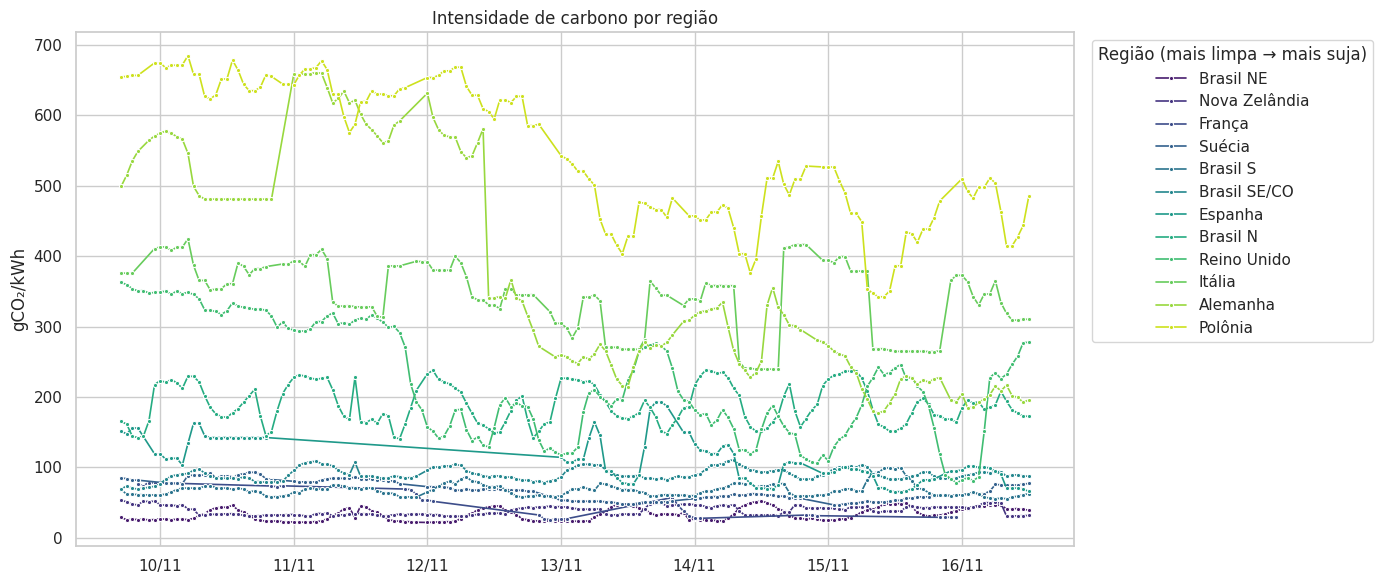

In [6]:
fig, ax = plt.subplots(figsize=(14, 6))
sns.lineplot(
    data=df, x="datetime", y="intensidade_gco2_kwh",
    hue="Região", hue_order=ordem, palette="viridis",
    marker="o", markersize=3, linewidth=1.2, ax=ax,
)
ax.set(title="Intensidade de carbono por região", xlabel="", ylabel="gCO₂/kWh")
ax.xaxis.set_major_locator(mdates.DayLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
ax.xaxis.set_minor_locator(mdates.HourLocator(byhour=[6, 12, 18]))
ax.legend(title="Região (mais limpa → mais suja)", bbox_to_anchor=(1.01, 1), loc="upper left")
fig.tight_layout()

## Uma região por gráfico (escala própria)

Text(0.5, 1.02, 'Intensidade de carbono — detalhe por região')

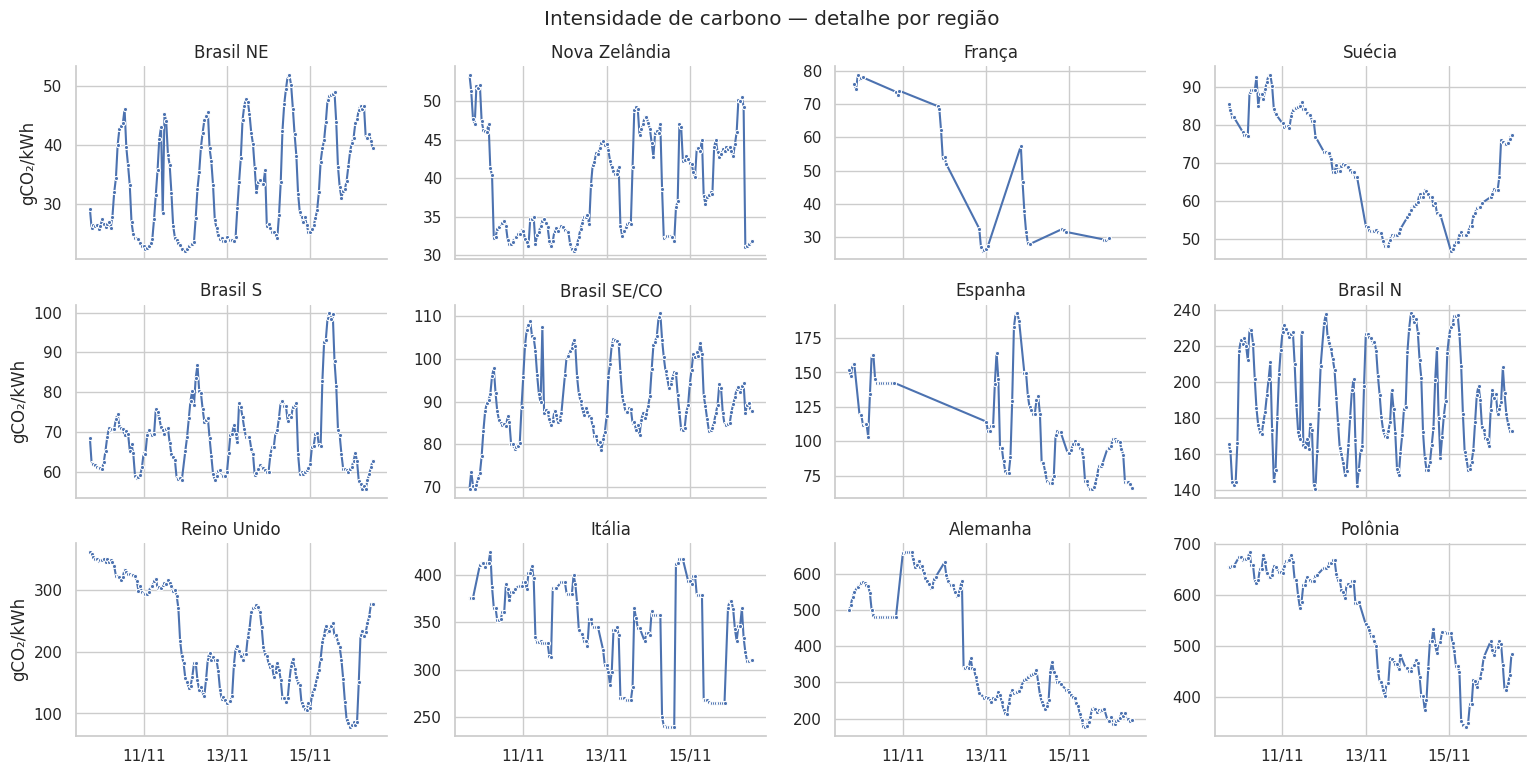

In [7]:
g = sns.relplot(
    data=df, x="datetime", y="intensidade_gco2_kwh",
    col="Região", col_order=ordem, col_wrap=4,
    kind="line", marker="o", markersize=3,
    height=2.6, aspect=1.5, facet_kws={"sharey": False},
)
g.set_titles("{col_name}")
g.set_axis_labels("", "gCO₂/kWh")
for ax in g.axes:
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
g.figure.suptitle("Intensidade de carbono — detalhe por região", y=1.02)

## Perfil médio por hora do dia

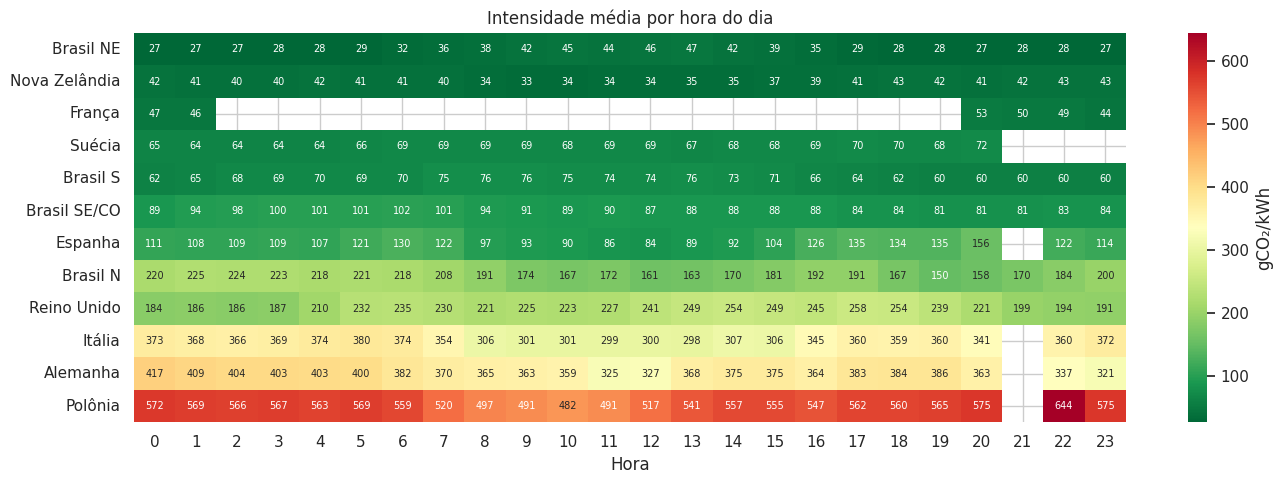

In [8]:
por_hora = (
    df.assign(hora=df["datetime"].dt.hour)
      .pivot_table(index="Região", columns="hora", values="intensidade_gco2_kwh", aggfunc="mean")
      .loc[ordem]
)
fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(por_hora, cmap="RdYlGn_r", annot=True, fmt=".0f", annot_kws={"size": 7},
            cbar_kws={"label": "gCO₂/kWh"}, ax=ax)
ax.set(title="Intensidade média por hora do dia", xlabel="Hora", ylabel="")
fig.tight_layout()

## Retirando elementos outliers

In [9]:
# Limite de corte: regiões com média acima disso são tratadas como outliers
LIMITE_MEDIA = 70  # gCO₂/kWh

# `resumo` já está na ordem da mais limpa para a mais suja, então a ordem se mantém
ordem_sem_outliers = resumo[resumo["media"] <= LIMITE_MEDIA].index.tolist()
df_sem_outliers = df[df["Região"].isin(ordem_sem_outliers)]

resumo.loc[ordem_sem_outliers].style.format("{:.1f}", subset=["media", "min", "max", "desvio"]) \
    .background_gradient(cmap="RdYlGn_r", subset=["media"]) \
    .bar(subset=["desvio"], color="#9ecae1")

,media,min,max,desvio,amostras
Região,,,,,
Brasil NE,33.4,22.0,51.9,8.8,163
Nova Zelândia,39.1,30.6,53.4,6.4,164
França,48.6,26.0,78.7,20.7,34
Suécia,67.6,46.9,93.1,13.7,137
Brasil S,68.0,55.7,99.8,8.9,163


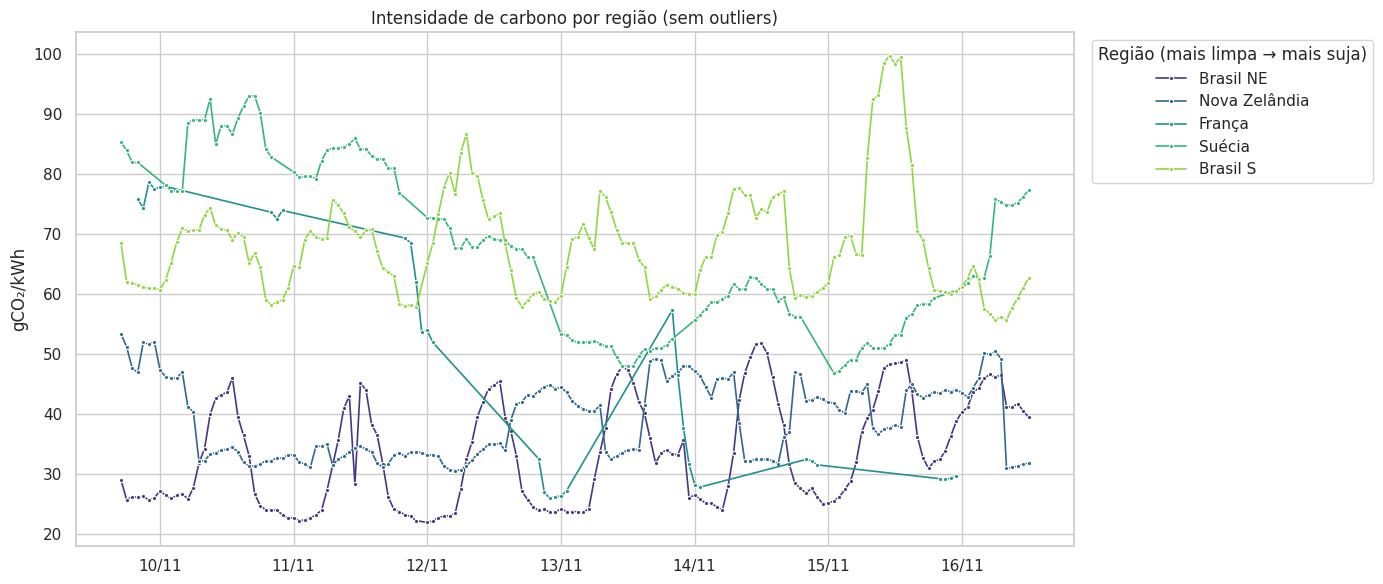

In [10]:
fig, ax = plt.subplots(figsize=(14, 6))
sns.lineplot(
    data=df_sem_outliers, x="datetime", y="intensidade_gco2_kwh",
    hue="Região", hue_order=ordem_sem_outliers, palette="viridis",
    marker="o", markersize=3, linewidth=1.2, ax=ax,
)
ax.set(title="Intensidade de carbono por região (sem outliers)", xlabel="", ylabel="gCO₂/kWh")
ax.xaxis.set_major_locator(mdates.DayLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
ax.xaxis.set_minor_locator(mdates.HourLocator(byhour=[6, 12, 18]))
ax.legend(title="Região (mais limpa → mais suja)", bbox_to_anchor=(1.01, 1), loc="upper left")
fig.tight_layout()